In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")


TensorFlow version: 2.21.0
Libraries imported successfully!


In [2]:

uploaded = files.upload()


Saving spam_sms.csv to spam_sms.csv


In [3]:

import io

filename = next(iter(uploaded))

df = pd.read_csv(
    io.BytesIO(uploaded[filename]),
    encoding="latin-1"
)

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())


Dataset shape: (5572, 2)
Column names: ['v1', 'v2']


,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


**Clean dataset**

In [4]:

# Detect common column names
columns = {str(c).strip().lower(): c for c in df.columns}

label_candidates = ["label", "v1", "category", "target"]
text_candidates = ["message", "text", "sms", "v2", "msg"]

label_col = next(
    (columns[c] for c in label_candidates if c in columns), None
)
text_col = next(
    (columns[c] for c in text_candidates if c in columns), None
)

if label_col is None or text_col is None:
    raise ValueError(
        "Could not identify label and message columns. "
        "Check the column names printed in Step 4."
    )

df = df[[label_col, text_col]].copy()
df.columns = ["label", "message"]

df = df.dropna(subset=["label", "message"])
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()

df = df[
    df["label"].isin(["ham", "spam"]) &
    (df["message"] != "")
]

df = df.drop_duplicates(subset=["label", "message"])
df = df.reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("\nLabel distribution:")
print(df["label"].value_counts())
display(df.head())


Cleaned dataset shape: (5158, 2)

Label distribution:
label
ham     4516
spam     642
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


**Apx 2000**

In [5]:

if df["label"].nunique() != 2 or df["label"].value_counts().min() < 2:
    raise ValueError("The dataset needs enough examples of both ham and spam.")

n_samples = min(2000, len(df))

df = df.sample(
    n=n_samples,
    random_state=42,
    stratify=df["label"] if False else None
) if False else df.groupby("label", group_keys=False).apply(
    lambda group: group.sample(
        n=round(n_samples * len(group) / len(df)),
        random_state=42
    )
)

# Adjust to exactly 2,000 if rounding caused a difference
if len(df) > n_samples:
    df = df.sample(n=n_samples, random_state=42)
elif len(df) < n_samples:
    remaining = data_remaining = None
    # Rebuild a stratified sample using scikit-learn below

print("Selected messages:", len(df))
print(df["label"].value_counts())


Selected messages: 2000
label
ham     1751
spam     249
Name: count, dtype: int64


/tmp/ipykernel_1663/2904122109.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ) if False else df.groupby("label", group_keys=False).apply(


In [6]:

from sklearn.model_selection import train_test_split

if len(df) > 2000:
    df, _ = train_test_split(
        df,
        train_size=2000,
        random_state=42,
        stratify=df["label"]
    )

df = df.reset_index(drop=True)

print("Final dataset size:", len(df))
print(df["label"].value_counts())


Final dataset size: 2000
label
ham     1751
spam     249
Name: count, dtype: int64


**Preprocess**

In [7]:

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " URL ", text)
    text = re.sub(r"\S+@\S+", " EMAIL ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_message"] = df["message"].apply(clean_text)

# Convert labels: ham = 0, spam = 1
df["label_num"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

display(df[["message", "clean_message", "label", "label_num"]].head())


,message,clean_message,label,label_num
0,"Come to me, slave. Your doing it again ... Goi...","come to me, slave. your doing it again ... goi...",ham,0
1,U meet other fren dun wan meet me ah... Muz b ...,u meet other fren dun wan meet me ah... muz b ...,ham,0
2,"G says you never answer your texts, confirm/deny","g says you never answer your texts, confirm/deny",ham,0
3,"K so am I, how much for an 8th? Fifty?","k so am i, how much for an 8th? fifty?",ham,0
4,HMM yeah if your not too grooved out! And im l...,hmm yeah if your not too grooved out! and im l...,ham,0


**split data**

In [8]:

X = df["clean_message"]
y = df["label_num"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))


Training messages: 1600
Testing messages: 400


**Tokenize**

In [9]:

vocab_size = 5000
max_length = 50

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

# Learn vocabulary only from training messages
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

print("Training input shape:", X_train_pad.shape)
print("Testing input shape:", X_test_pad.shape)
print("Example numerical sequence:", X_train_pad[0])


Training input shape: (1600, 50)
Testing input shape: (400, 50)
Example numerical sequence: [ 920    6  921  215   32 1862  636  104 1863   20  922    8 1228  173
   97  637   20 1864    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0]


**LSTM Model**

In [10]:

model = Sequential([
    Embedding(
        input_dim=5000,
        output_dim=32,
        mask_zero=True
    ),
    LSTM(32),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

**Train Model**

In [11]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.8570 - loss: 0.5824 - val_accuracy: 0.8656 - val_loss: 0.4646
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9008 - loss: 0.2625 - val_accuracy: 0.9406 - val_loss: 0.1895
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9867 - loss: 0.0925 - val_accuracy: 0.9625 - val_loss: 0.1320
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9961 - loss: 0.0371 - val_accuracy: 0.9719 - val_loss: 0.1217
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9961 - loss: 0.0186 - val_accuracy: 0.9688 - val_loss: 0.1227
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9992 - loss: 0.0091 - val_accuracy: 0.9719 - val_loss: 0.1323


In [12]:

y_prob = model.predict(X_test_pad).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    zero_division=0
))


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step
Accuracy : 0.9875
Precision: 0.9245283018867925
Recall   : 0.98
F1-score : 0.9514563106796117

Classification Report:
              precision    recall  f1-score   support

         Ham       1.00      0.99      0.99       350
        Spam       0.92      0.98      0.95        50

    accuracy                           0.99       400
   macro avg       0.96      0.98      0.97       400
weighted avg       0.99      0.99      0.99       400



In [13]:
y_prob = model.predict(X_test_pad).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred, zero_division=0))

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
Accuracy : 0.9875
Precision: 0.9245283018867925
Recall   : 0.98
F1-score : 0.9514563106796117


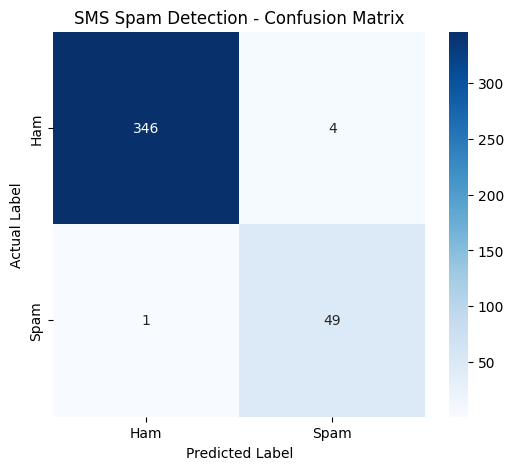

Confusion Matrix:
[[346   4]
 [  1  49]]


In [14]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SMS Spam Detection - Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)


**Training time **

In [16]:
train_loss, train_accuracy = model.evaluate(
    X_train_pad, y_train, verbose=0
)

print(f"Training Accuracy: {train_accuracy * 100:.2f}%")

Training Accuracy: 99.31%


**Test New SMS**

In [15]:

def predict_sms(message):
    cleaned = clean_text(message)

    sequence = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(
        sequence,
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    probability = float(
        model.predict(padded, verbose=0)[0][0]
    )

    prediction = "SPAM" if probability >= 0.5 else "HAM"

    print("Message:", message)
    print("Prediction:", prediction)
    print(f"Spam score: {probability:.2%}")
    print("-" * 40)


predict_sms("Congratulations! You won a free gift. Claim now!")
predict_sms("Hey, are you coming to college tomorrow?")
predict_sms("URGENT! Claim your cash prize now!")
predict_sms("Your appointment is confirmed for tomorrow.")


Message: Congratulations! You won a free gift. Claim now!
Prediction: SPAM
Spam score: 65.58%
----------------------------------------
Message: Hey, are you coming to college tomorrow?
Prediction: HAM
Spam score: 0.11%
----------------------------------------
Message: URGENT! Claim your cash prize now!
Prediction: SPAM
Spam score: 83.67%
----------------------------------------
Message: Your appointment is confirmed for tomorrow.
Prediction: HAM
Spam score: 3.66%
----------------------------------------


In [17]:
predict_sms("Congratulations! You have won a free mobile phone. Click here to claim your prize now!")

Message: Congratulations! You have won a free mobile phone. Click here to claim your prize now!
Prediction: SPAM
Spam score: 95.64%
----------------------------------------
